# Giảm chiều dữ liệu văn bản bằng PCA và SVD để phát hiện SMS spam

**Đồ án Toán cho Khoa học Máy tính và Machine Learning — Python, quy mô sinh viên.**
Trình bày theo thứ tự **giải thích → code → output thật → nhận xét**, như một bài thực hành có thể chạy lại.

## 1. Bài toán và câu hỏi nghiên cứu

Đầu vào là một SMS tiếng Anh. Đầu ra là nhãn **ham** (bình thường) hoặc **spam** (tin nhắn rác), cùng xác suất spam ước lượng.
Ta dùng Logistic Regression làm classifier chung để tập trung vào PCA/SVD.

- Giảm từ 1.000 đặc trưng TF-IDF xuống k chiều ảnh hưởng thế nào đến phân loại?
- Khi tăng k, variance/energy giữ lại và macro-F1 thay đổi thế nào?
- Giảm chiều có thực sự giảm thời gian và dung lượng biểu diễn không?

```text
SMS → làm sạch → chia tập → TF-IDF
                           ├─ A. Logistic Regression (baseline)
                           ├─ B. Dense → PCA → Logistic Regression
                           └─ C. Truncated SVD → Logistic Regression
```

## 2. Chuẩn bị thư viện

Tất cả phép học diễn ra trên CPU. Các helper trong `src/` giữ cùng một cách xử lý ở notebook và chương trình terminal.
Ô đầu tự kiểm tra và cài các thư viện còn thiếu bằng Python của kernel hiện tại.


In [1]:
from pathlib import Path
import os
import sys

# Tìm project trước khi nạp các module src, kể cả khi kernel ở thư mục con.
PROJECT_ROOT = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "src").is_dir() and (folder / "requirements.txt").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục project chứa src/ và requirements.txt.")
os.chdir(PROJECT_ROOT)
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".mplconfig"))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from scripts.notebook_setup import ensure_dependencies

ensure_dependencies(PROJECT_ROOT)

import io
import json
import unittest

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from threadpoolctl import threadpool_limits

from src.data import DEFAULT_DATA, download_data
from src.models import make_pipeline, K_VALUES
from src.math_demo import run_demo
from src.train import (
    prepare_output_and_logger, prepare_data_and_audit, fit_evaluate,
    feature_fingerprint, choose_k, refit_and_evaluate_test,
    save_run_config, save_json,
)
from src.plots import make_plots
from src.predict import predict_message

cpu_limit = threadpool_limits(limits=1)
OUTPUT_ROOT = Path("outputs")
results, logger = prepare_output_and_logger(OUTPUT_ROOT)

# Bảng Markdown không cần thêm dependency tabulate.
def show_table(frame):
    table = frame.copy()
    for column in table.columns:
        table[column] = table[column].map(
            lambda x: f"{x:.4f}" if isinstance(x, (float, np.floating)) and pd.notna(x)
            else ("—" if pd.isna(x) else str(x).replace("|", r"\|").replace("\n", " "))
        )
    lines = ["| " + " | ".join(map(str, table.columns)) + " |",
             "| " + " | ".join(["---"] * len(table.columns)) + " |"]
    lines += ["| " + " | ".join(row) + " |" for row in table.to_numpy().tolist()]
    display(Markdown("\n".join(lines)))

print(f"Python đang chạy: {sys.executable}")
print("Đã nạp thư viện. CPU: một BLAS thread; seed mặc định: 42.")


Python đang chạy: D:\Python\python.exe
Đã nạp thư viện. CPU: một BLAS thread; seed mặc định: 42.


## 3. Dataset, làm sạch và chia tập

Dùng [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection).
Mỗi dòng gồm `nhãn<TAB>tin nhắn`. Dataset gốc đọc được 5.574 dòng.
Chữ thường và khoảng trắng được chuẩn hóa; giữ một bản cho mỗi nội dung. Nếu cùng nội dung có nhãn mâu thuẫn thì loại cả nhóm.

Chia gần **70% train / 15% validation / 15% test**, stratification giữ tỷ lệ hai lớp gần nhau, seed 42.

| Tập | Vai trò |
|---|---|
| Train | Học vocabulary, IDF, mean PCA, hướng chiếu và classifier |
| Validation | Chọn k trong grid |
| Test | Đánh giá cuối sau khi khóa cấu hình |

**fit** nghĩa là học tham số; **transform** dùng tham số đã học để biến đổi dữ liệu;
**predict** đưa biểu diễn đã biến đổi vào classifier để trả nhãn.
Token chỉ có trong validation/test không được bổ sung vào vocabulary train.


In [2]:
if not DEFAULT_DATA.is_file():
    download_data()  # Chỉ cần Internet khi chưa có file UCI cục bộ.

splits = prepare_data_and_audit(DEFAULT_DATA, results, logger)
audit = json.loads((results / "data_summary.json").read_text(encoding="utf-8"))
print(f"Dòng gốc: {audit['raw_rows']}; bản trùng loại: {audit['duplicates_removed']}; "
      f"còn: {audit['clean_rows']}")
summary = pd.DataFrame([
    {"Tập": name, "Tổng": len(part),
     "Ham": int(part.label.eq("ham").sum()), "Spam": int(part.label.eq("spam").sum())}
    for name, part in splits.items()
])
show_table(summary)
show_table(splits["train"][["label", "text"]].head(3).assign(
    text=lambda frame: frame.text.str.slice(0, 100)))


Dữ liệu: {"raw_rows": 5574, "empty_removed": 0, "conflicting_groups": 0, "conflicting_rows_removed": 0, "duplicates_removed": 415, "clean_rows": 5159, "class_counts": {"ham": 4517, "spam": 642}, "splits": {"train": {"rows": 3611, "class_counts": {"ham": 3162, "spam": 449}}, "validation": {"rows": 774, "class_counts": {"ham": 677, "spam": 97}}, "test": {"rows": 774, "class_counts": {"ham": 678, "spam": 96}}}, "raw_file_sha256": "7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d"}


Dòng gốc: 5574; bản trùng loại: 415; còn: 5159


| Tập | Tổng | Ham | Spam |
| --- | --- | --- | --- |
| train | 3611 | 3162 | 449 |
| validation | 774 | 677 | 97 |
| test | 774 | 678 | 96 |

| label | text |
| --- | --- |
| ham | what time you thinkin of goin? |
| spam | wanna have a laugh? try chit-chat on your mobile now! logon by txting the word: chat and send it to  |
| ham | what is this 'hex' place you talk of? explain! |

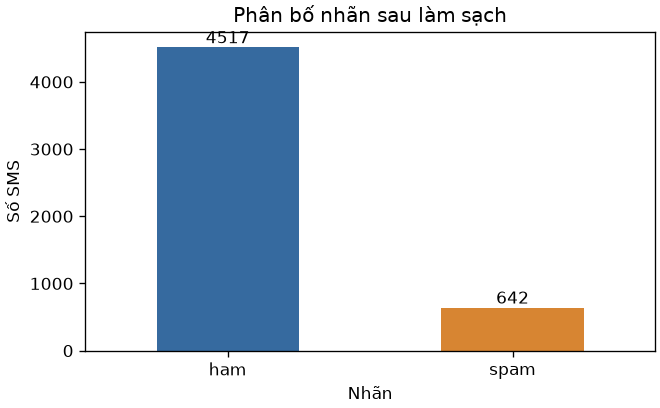

In [3]:
counts = pd.Series(audit["class_counts"]).reindex(["ham", "spam"])
fig, ax = plt.subplots(figsize=(5.5, 3.4), layout="constrained")
counts.plot.bar(ax=ax, rot=0, color=["#366a9f", "#d78532"])
ax.set(title="Phân bố nhãn sau làm sạch", xlabel="Nhãn", ylabel="Số SMS")
for position, count in enumerate(counts):
    ax.text(position, count, str(count), ha="center", va="bottom")
fig.savefig("outputs/figures/class_distribution.png", dpi=120)
plt.close(fig)
display(Image(filename="outputs/figures/class_distribution.png"))


Ham nhiều hơn spam, nên accuracy cao vẫn có thể đi kèm bỏ sót nhiều spam.
Ta sẽ dùng **macro-F1** để chọn k, đồng thời đọc **spam recall** khi đánh giá cuối.

## 4. TF-IDF: chuyển văn bản thành ma trận nhiều chiều

Với N SMS và D từ, $X\in\mathbb{R}^{N\times D}$: mỗi hàng là một SMS, mỗi cột là một từ.
Từ không xuất hiện trong SMS nhận zero. Cấu hình tối đa 1.000 từ, unigram,
`min_df=2`, `sublinear_tf=True`, chuẩn hóa L2. Với tần suất $f>0$:

$$
\operatorname{tf}(f)=1+\log f,\qquad
\operatorname{idf}(t)=\log\frac{1+N}{1+\operatorname{df}(t)}+1.
$$

Nhân TF và IDF, rồi chuẩn hóa từng hàng. `df(t)` được tính từ train.
CSR là cách lưu sparse, chỉ lưu giá trị khác zero và các chỉ số liên quan.
Ô dưới minh họa TF-IDF trên train; các pipeline thí nghiệm sẽ tự fit cùng cấu hình trên đúng tập học.


In [4]:
vectorizer = make_pipeline().named_steps["tfidf"]
X_train = vectorizer.fit_transform(splits["train"].text)
D = X_train.shape[1]
csr_bytes = X_train.data.nbytes + X_train.indices.nbytes + X_train.indptr.nbytes
print("Shape TF-IDF train:", X_train.shape)
print(f"Mật độ khác zero: {X_train.nnz / (X_train.shape[0] * D):.4%}")
print(f"CSR: {csr_bytes:,} byte; nếu dense: {X_train.shape[0] * D * 8:,} byte")

first_sms = X_train[0].toarray().ravel()
positions = np.flatnonzero(first_sms)[:8]
show_table(pd.DataFrame({"Từ trong SMS đầu": vectorizer.get_feature_names_out()[positions],
                         "TF-IDF": first_sms[positions]}))


Shape TF-IDF train: (3611, 1000)
Mật độ khác zero: 1.0386%
CSR: 464,496 byte; nếu dense: 28,888,000 byte


| Từ trong SMS đầu | TF-IDF |
| --- | --- |
| goin | 0.5445 |
| of | 0.2807 |
| thinkin | 0.5874 |
| time | 0.3658 |
| what | 0.3331 |
| you | 0.1869 |

## 5. SVD và xấp xỉ hạng thấp bằng NumPy

Với rank r, SVD dạng compact:

$$X=U\Sigma V^T,\qquad X_k=U_k\Sigma_kV_k^T,\qquad Z=XV_k=U_k\Sigma_k.$$

U có kích thước N×r, V là D×r, các cột là left/right singular vectors.
Các singular values $\sigma_j$ nằm trên đường chéo của $\Sigma$, sắp giảm dần.
Rank là số hướng tuyến tính độc lập. Giữ k hướng cho Z kích thước N×k.

**Giảm còn 100 chiều là tạo 100 tổ hợp tuyến tính, không phải chọn 100 từ.**
Với SVD exact, sai số tái tạo tối ưu theo chuẩn Frobenius:

$$\|X-X_k\|_F^2=\sum_{j>k}\sigma_j^2.$$

Ta kiểm chứng trên ma trận 6×4; dữ liệu nhỏ này chỉ minh họa toán, không dùng thay dataset SMS.


In [5]:
math_result = run_demo()
save_json(results / "math_demo.json", math_result)
X_small = np.array(math_result["matrix"])
U, singular_values, Vt = np.linalg.svd(X_small, full_matrices=False)
k_demo = 2
Z_small = X_small @ Vt[:k_demo].T
X_small_k = Z_small @ Vt[:k_demo]
squared_error = np.linalg.norm(X_small - X_small_k, "fro") ** 2
tail_energy = np.sum(singular_values[k_demo:] ** 2)
np.testing.assert_allclose(squared_error, tail_energy, atol=1e-8)
print("X:")
print(np.round(X_small, 3))
print("Shape U, singular values, Vt:", U.shape, singular_values.shape, Vt.shape)
print("Singular values:", np.round(singular_values, 4))
print("Shape Z với k=2:", Z_small.shape)
print(f"Sai số bình phương: {squared_error:.6f}; tổng sigma bị bỏ bình phương: {tail_energy:.6f}")


X:
[[ 3.914 -3.928  5.542  0.951]
 [-2.853 -5.58   4.867  0.386]
 [ 2.95  -3.714  5.709  0.899]
 [ 3.198  0.287  5.693  0.203]
 [ 4.106 -3.733  5.687  0.568]
 [ 2.445 -3.454  6.086  0.56 ]]
Shape U, singular values, Vt: (6, 4) (4,) (4, 4)
Singular values: [17.1679  6.3932  2.6738  0.3411]
Shape Z với k=2: (6, 2)
Sai số bình phương: 7.265551; tổng sigma bị bỏ bình phương: 7.265551


## 6. PCA và mối liên hệ với SVD

PCA trừ mean từng cột rồi chọn các hướng có variance lớn:

$$X_c=X-\mu,\qquad C=\frac{X_c^TX_c}{N-1},\qquad Z=X_cW_k.$$

Nếu $X_c=U\Sigma V^T$, suy ra:

$$C=V\frac{\Sigma^2}{N-1}V^T,\qquad \lambda_j=\frac{\sigma_j^2}{N-1},\qquad W_k=V_k.$$

Đây là liên hệ cốt lõi: **PCA có thể tính bằng SVD của dữ liệu đã center**.
Truncated SVD trực tiếp trên TF-IDF không center, nên nhìn chung khác PCA.
Ô sau tự tính mean, covariance, eigenvectors và phép chiếu bằng NumPy.


In [6]:
mean = X_small.mean(axis=0)
X_centered = X_small - mean
covariance = X_centered.T @ X_centered / (len(X_small) - 1)
eigenvalues, eigenvectors = np.linalg.eigh(covariance)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
W = eigenvectors[:, order[:k_demo]]
Z_pca = X_centered @ W

_, centered_singular_values, centered_Vt = np.linalg.svd(X_centered, full_matrices=False)
values_from_svd = centered_singular_values**2 / (len(X_small) - 1)
projector_error = np.linalg.norm(W @ W.T - centered_Vt[:k_demo].T @ centered_Vt[:k_demo])
np.testing.assert_allclose(eigenvalues, values_from_svd, atol=1e-8)
np.testing.assert_allclose(projector_error, 0, atol=1e-8)
print("Eigenvalues:", np.round(eigenvalues, 6))
print("Sigma²/(N-1):", np.round(values_from_svd, 6))
print(f"Sai số projector PCA/SVD: {projector_error:.3e}")
print(f"Sai số tái tạo SVD đầy đủ: {math_result['full_reconstruction_error']:.3e}")
show_table(pd.DataFrame(math_result["errors_by_k"])[
    ["k", "svd_reconstruction_error", "pca_reconstruction_error"]])


Eigenvalues: [8.322617 2.338056 0.061063 0.022858]
Sigma²/(N-1): [8.322617 2.338056 0.061063 0.022858]
Sai số projector PCA/SVD: 8.900e-16
Sai số tái tạo SVD đầy đủ: 1.237e-14


| k | svd_reconstruction_error | pca_reconstruction_error |
| --- | --- | --- |
| 1 | 6.9382 | 3.4799 |
| 2 | 2.6955 | 0.6478 |
| 3 | 0.3411 | 0.3381 |
| 4 | 0.0000 | 0.0000 |

Vector khác dấu vẫn có thể chỉ cùng một hướng, nên ta so **projector** của không gian con.
Sai số tái tạo giảm khi tăng k; PCA có thêm bước xử lý mean, cần giữ khác biệt này khi diễn giải hai cột.

Với TF-IDF thật, trừ mean trực tiếp làm nhiều zero thành khác zero. Nhánh PCA chuyển dense
và kiểm tra giới hạn 128 MiB cho ma trận đầu vào; đây chưa phải peak RAM.
Covariance chỉ được dựng trong demo nhỏ. Trên văn bản, PCA dùng solver randomized;
Truncated SVD nhận sparse input trực tiếp.

## 7. Xây ba pipeline và huấn luyện trên train

Logistic Regression học một hàm điểm tuyến tính rồi dùng sigmoid để ước lượng xác suất spam.
Dù có tên Regression, đây là classifier. Giữ C=1, L2, `max_iter=2000`, ngưỡng phân loại 0,5.
Hai reducer cùng seed 42, PCA không whitening. Baseline giữ nguyên TF-IDF.


In [7]:
for method in ["baseline", "pca", "svd"]:
    pipeline = make_pipeline(method, None if method == "baseline" else 50)
    print(method.upper(), "→", " → ".join(
        type(step).__name__ for _, step in pipeline.steps))


BASELINE → TfidfVectorizer → LogisticRegression
PCA → TfidfVectorizer → ToDense → PCA → LogisticRegression
SVD → TfidfVectorizer → TruncatedSVD → LogisticRegression


### 7.1. Thử k bằng validation

Dùng k∈{10,50,100}, chỉ lấy giá trị hợp lệ theo kích thước train và D.
`fit_evaluate` gọi fit trên train, predict trên validation, trả model và một dòng metrics.
Thời gian fit bao gồm cả TF-IDF, reducer/chuyển dense nếu có và classifier.

**Macro-F1** là trung bình F1 hai lớp với trọng số bằng nhau. Spam precision đo độ đúng
khi báo spam; spam recall đo tỷ lệ spam thực sự được bắt; spam-F1 kết hợp precision và recall.


In [8]:
baseline, baseline_row, _ = fit_evaluate(
    "baseline", None, splits["train"], splits["validation"], "validation")
validation_rows = [baseline_row]
candidate_k = [k for k in K_VALUES if 1 <= k < min(len(splits["train"]) - 1, D)]
assert candidate_k, "Dataset quá nhỏ cho grid đã chọn."

for method in ["pca", "svd"]:
    for k in candidate_k:
        _, row, _ = fit_evaluate(method, k, splits["train"], splits["validation"], "validation")
        validation_rows.append(row)
        logger.info("Validation %s k=%d: macro-F1=%.6f; fit=%.4fs", method, k,
                    row["macro_f1"], row["fit_seconds"])

validation = pd.DataFrame(validation_rows)
assert validation.feature_fingerprint.nunique() == 1  # Cùng vocabulary và IDF.
validation.to_csv(results / "validation_metrics.csv", index=False)
show_table(validation[["method", "k", "accuracy", "macro_f1", "spam_recall", "fit_seconds"]])


Validation pca k=10: macro-F1=0.843138; fit=0.3928s


Validation pca k=50: macro-F1=0.893168; fit=0.5219s


Validation pca k=100: macro-F1=0.899132; fit=0.5376s


Validation svd k=10: macro-F1=0.843138; fit=0.1685s


Validation svd k=50: macro-F1=0.897044; fit=0.1978s


Validation svd k=100: macro-F1=0.901890; fit=0.2756s


| method | k | accuracy | macro_f1 | spam_recall | fit_seconds |
| --- | --- | --- | --- | --- | --- |
| baseline | — | 0.9716 | 0.9288 | 0.7835 | 0.1290 |
| pca | 10.0000 | 0.9406 | 0.8431 | 0.6082 | 0.3928 |
| pca | 50.0000 | 0.9587 | 0.8932 | 0.7010 | 0.5219 |
| pca | 100.0000 | 0.9599 | 0.8991 | 0.7320 | 0.5376 |
| svd | 10.0000 | 0.9406 | 0.8431 | 0.6082 | 0.1685 |
| svd | 50.0000 | 0.9599 | 0.8970 | 0.7113 | 0.1978 |
| svd | 100.0000 | 0.9612 | 0.9019 | 0.7320 | 0.2756 |

### 7.2. Khóa k trước khi xem test

Chọn macro-F1 validation cao nhất từng phương pháp; hòa thì chọn k nhỏ hơn.
Đây chỉ là lựa chọn tốt nhất trong grid đã thử. Sau bước này mới refit trên train + validation,
đánh giá test và lưu pipeline. Không chọn lại k từ điểm test.


In [9]:
selected = {method: choose_k(validation, method) for method in ["pca", "svd"]}
save_json(results / "selected_k.json", {
    "criterion": "Maximum validation macro-F1; ties choose smaller k",
    "selected_k": selected, "candidate_k": candidate_k,
})
logger.info("Đã khóa k theo validation: %s", selected)
print("k được chọn:", selected)
print("Số mẫu refit:", len(splits["train"]) + len(splits["validation"]))

refit_and_evaluate_test(splits, selected, OUTPUT_ROOT, logger)
save_run_config(results, candidate_k)
make_plots(OUTPUT_ROOT)
test_metrics = pd.read_csv(results / "test_metrics.csv")
show_table(test_metrics[["method", "k", "accuracy", "macro_f1", "spam_precision", "spam_recall", "spam_f1"]])


Đã khóa k theo validation: {'pca': 100, 'svd': 100}


k được chọn: {'pca': 100, 'svd': 100}
Số mẫu refit: 4385


TEST baseline: accuracy=0.972868 macro-F1=0.930971 spam-recall=0.781250


TEST pca: accuracy=0.954780 macro-F1=0.875954 spam-recall=0.635417


TEST svd: accuracy=0.953488 macro-F1=0.871684 spam-recall=0.625000


| method | k | accuracy | macro_f1 | spam_precision | spam_recall | spam_f1 |
| --- | --- | --- | --- | --- | --- | --- |
| baseline | — | 0.9729 | 0.9310 | 1.0000 | 0.7812 | 0.8772 |
| pca | 100.0000 | 0.9548 | 0.8760 | 1.0000 | 0.6354 | 0.7771 |
| svd | 100.0000 | 0.9535 | 0.8717 | 1.0000 | 0.6250 | 0.7692 |

## 8. Đồ thị kết quả và nhận xét

### 8.1. Macro-F1 theo k trên validation


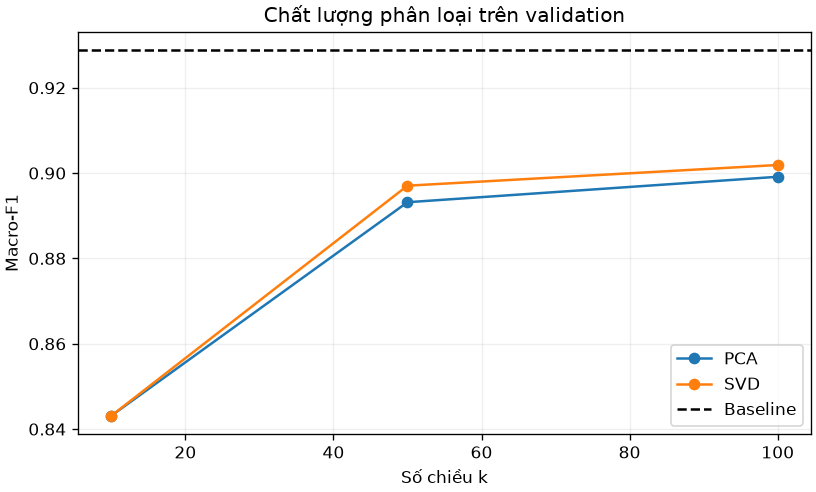

In [10]:
display(Image(filename="outputs/figures/validation_f1.png"))


Trong grid này, tăng k cải thiện macro-F1; cả PCA và SVD chọn k=100 nhưng chưa đạt baseline.
Lượng phương sai/năng lượng lớn không tự bảo đảm giữ đủ tín hiệu cần cho nhãn.

### 8.2. Confusion matrix trên test

Hàng là nhãn thật, cột là nhãn dự đoán.
**False positive:** ham bị báo spam. **False negative:** spam bị bỏ sót thành ham.


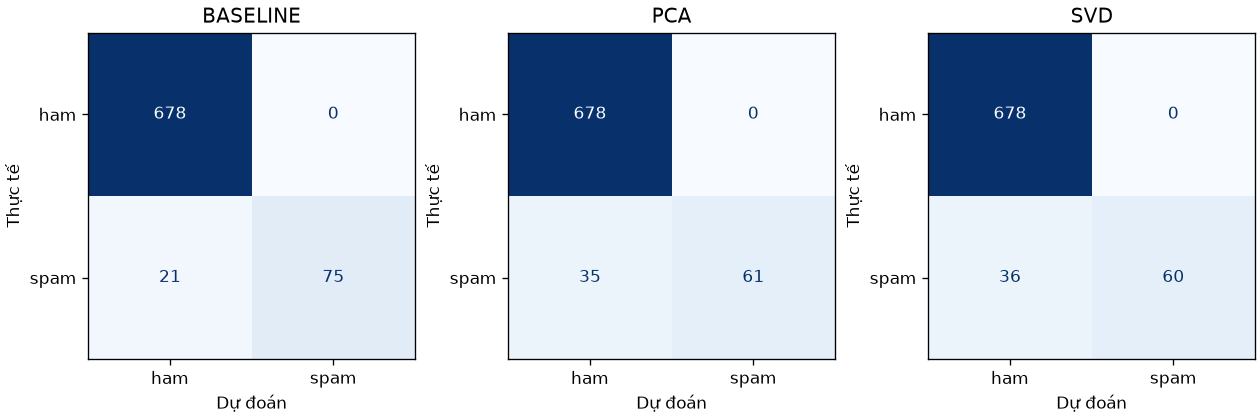

baseline: bắt 75/96 spam, bỏ sót 21; ham bị báo spam: 0
pca: bắt 61/96 spam, bỏ sót 35; ham bị báo spam: 0
svd: bắt 60/96 spam, bỏ sót 36; ham bị báo spam: 0


In [11]:
display(Image(filename="outputs/figures/test_confusion.png"))
matrices = json.loads((results / "confusion_matrices.json").read_text(encoding="utf-8"))
for method, matrix in matrices["matrices"].items():
    caught, missed = matrix[1][1], matrix[1][0]
    print(f"{method}: bắt {caught}/{caught + missed} spam, bỏ sót {missed}; "
          f"ham bị báo spam: {matrix[0][1]}")


Baseline bắt spam tốt hơn hai mô hình giảm chiều trong test này. Precision bằng 1 ở tập test
không có nghĩa mọi SMS tương lai đều được dự đoán đúng.

### 8.3. Phương sai PCA và năng lượng SVD

$$R_{PCA}=\frac{\sum_{j\le k}\lambda_j}{\sum_j\lambda_j},\qquad
E_{SVD}=\frac{\|XV_k\|_F^2}{\|X\|_F^2}.$$

Hai đại lượng có centering khác nhau, không coi là cùng một tỷ lệ “thông tin ngôn ngữ”.
Biểu đồ dưới dùng train 3.611 mẫu, không phải tập test.


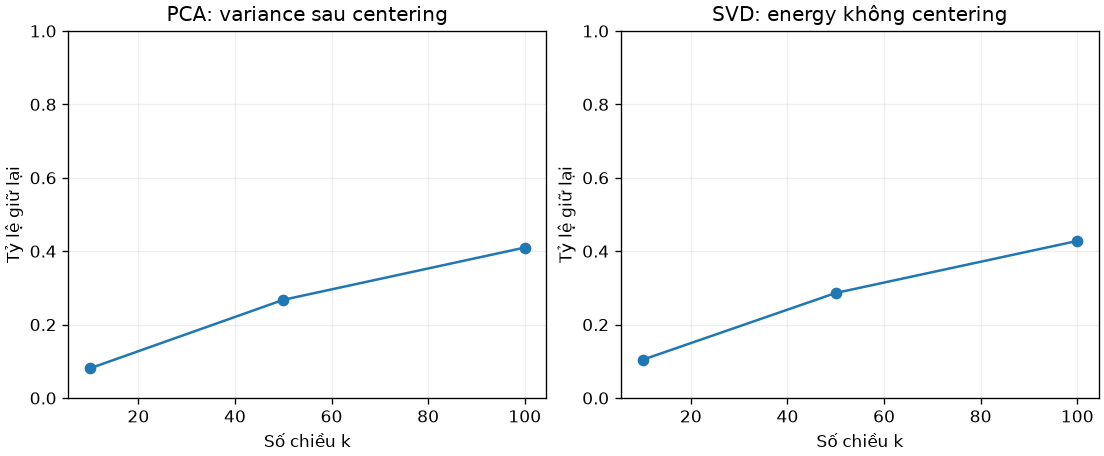

| method | k | pca_variance_retention | svd_energy_retention |
| --- | --- | --- | --- |
| pca | 10.0000 | 0.0809 | — |
| pca | 50.0000 | 0.2675 | — |
| pca | 100.0000 | 0.4099 | — |
| svd | 10.0000 | — | 0.1041 |
| svd | 50.0000 | — | 0.2862 |
| svd | 100.0000 | — | 0.4280 |

In [12]:
display(Image(filename="outputs/figures/retention.png"))
show_table(validation.loc[validation.method.ne("baseline"),
    ["method", "k", "pca_variance_retention", "svd_energy_retention"]])


### 8.4. Thời gian và dung lượng thực tế

Fit được đo một lần mỗi cấu hình, một BLAS thread. Inference đo toàn pipeline trên cùng batch,
lấy median năm lượt sau warm-up. Thời gian phụ thuộc máy và có thể không tăng đều theo k.


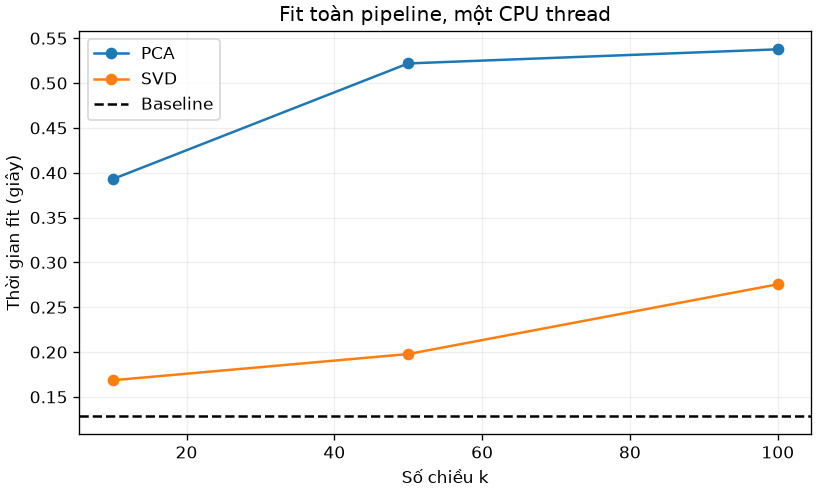

| method | fit_seconds | inference_batch_seconds |
| --- | --- | --- |
| baseline | 0.1293 | 0.0208 |
| pca | 0.6794 | 0.0255 |
| svd | 0.3021 | 0.0190 |

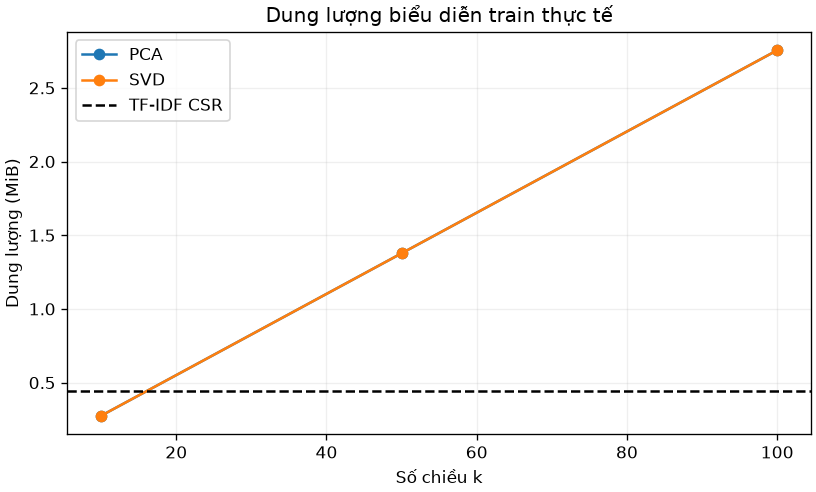

| method | D | output_dimensions | dimension_reduction | tfidf_csr_bytes | representation_bytes | pca_dense_input_bytes |
| --- | --- | --- | --- | --- | --- | --- |
| baseline | 1000 | 1000 | 0.0000 | 563448 | 563448 | 0 |
| pca | 1000 | 100 | 0.9000 | 563448 | 3508000 | 35080000 |
| svd | 1000 | 100 | 0.9000 | 563448 | 3508000 | 0 |

In [13]:
display(Image(filename="outputs/figures/fit_time.png"))
show_table(test_metrics[["method", "fit_seconds", "inference_batch_seconds"]])
display(Image(filename="outputs/figures/representation_size.png"))
show_table(test_metrics[["method", "D", "output_dimensions", "dimension_reduction",
                         "tfidf_csr_bytes", "representation_bytes", "pca_dense_input_bytes"]])


Hình đo train khi khảo sát k; bảng đo refit train + validation.
Giảm từ 1.000 xuống 100 chiều là giảm 90% số cột, nhưng Z là dense còn TF-IDF gốc rất sparse,
nên dung lượng representation có thể tăng. Số byte trên là kích thước mảng, chưa phải peak RAM.

## 9. Demo một tin nhắn mới

Model `.joblib` chứa cả TF-IDF, reducer và classifier. Dự đoán dùng pipeline đã lưu, không fit lại.
Demo chỉ minh họa cách sử dụng; đánh giá chính là trên 774 mẫu test.


In [14]:
messages = [
    "Can we meet at the library tomorrow?",
    "Congratulations! You have won a free prize. Call now to claim your cash reward!",
]
demo_rows = []
for method in ["baseline", "pca", "svd"]:
    saved_model = joblib.load(f"outputs/models/{method}.joblib")
    for message in messages:
        demo_rows.append({"method": method, **predict_message(saved_model, message)})
show_table(pd.DataFrame(demo_rows))
print(json.dumps(demo_rows[-1], ensure_ascii=False, indent=2))


| method | text | prediction | spam_probability |
| --- | --- | --- | --- |
| baseline | Can we meet at the library tomorrow? | ham | 0.0152 |
| baseline | Congratulations! You have won a free prize. Call now to claim your cash reward! | spam | 0.9683 |
| pca | Can we meet at the library tomorrow? | ham | 0.0158 |
| pca | Congratulations! You have won a free prize. Call now to claim your cash reward! | spam | 0.9849 |
| svd | Can we meet at the library tomorrow? | ham | 0.0153 |
| svd | Congratulations! You have won a free prize. Call now to claim your cash reward! | spam | 0.9861 |

{
  "method": "svd",
  "text": "Congratulations! You have won a free prize. Call now to claim your cash reward!",
  "prediction": "spam",
  "spam_probability": 0.9860611766640226
}


Xác suất spam là ước lượng của classifier, chưa được hiệu chỉnh riêng.

## 10. Kiểm tra tính đúng

Các tests kiểm tra phép phân rã, mean train, dữ liệu trùng, token validation không lọt vocabulary,
sparse/dense và lưu/load pipeline. Các tests bổ sung kiểm tra chuyển notebook thành Markdown.


In [15]:
test_suite = unittest.defaultTestLoader.discover("tests")
test_log = io.StringIO()
test_result = unittest.TextTestRunner(stream=test_log, verbosity=1).run(test_suite)
(results / "test_output.txt").write_text(test_log.getvalue(), encoding="utf-8")
print(test_log.getvalue())
assert test_result.wasSuccessful(), "Cần sửa tests trước khi kết luận hoàn tất."
print(f"Đạt {test_result.testsRun} tests.")


............................
----------------------------------------------------------------------
Ran 28 tests in 0.208s

OK

Đạt 28 tests.


## 11. Kết luận và giới hạn


In [16]:
baseline_f1 = test_metrics.loc[test_metrics.method.eq("baseline"), "macro_f1"].iloc[0]
observations = []
for method in ["pca", "svd"]:
    row = test_metrics.loc[test_metrics.method.eq(method)].iloc[0]
    observations.append({
        "Phương pháp": method.upper(), "k": int(row.output_dimensions),
        "Giảm chiều (%)": 100 * row.dimension_reduction,
        "Macro-F1 test": row.macro_f1, "Giảm F1 so baseline": baseline_f1 - row.macro_f1,
        "Dung lượng Z/CSR": row.representation_bytes / row.tfidf_csr_bytes,
    })
show_table(pd.DataFrame(observations))


| Phương pháp | k | Giảm chiều (%) | Macro-F1 test | Giảm F1 so baseline | Dung lượng Z/CSR |
| --- | --- | --- | --- | --- | --- |
| PCA | 100 | 90.0000 | 0.8760 | 0.0550 | 6.2260 |
| SVD | 100 | 90.0000 | 0.8717 | 0.0593 | 6.2260 |

**Trong phạm vi thí nghiệm này:** baseline phân loại tốt nhất. Giảm chiều mạnh làm giảm khả năng bắt spam,
và ở k=100 chưa tiết kiệm tổng thời gian hoặc dung lượng biểu diễn. Đây là một kết quả có ý nghĩa:
phép xấp xỉ ma trận tối ưu không tự động tối ưu tín hiệu phân loại.

Giới hạn: một split, ba k, vocabulary 1.000 từ, SMS tiếng Anh; chưa kiểm định ý nghĩa thống kê,
chưa hiệu chỉnh xác suất. k=100 là tốt nhất trong grid hiện tại, không phải mọi giá trị k.

## 12. Tài liệu tham khảo

- [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection).
- [PCA — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).
- [Truncated SVD — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html).
